In [31]:
from qiskit.circuit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.visualization import plot_histogram

from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

In [26]:
service = QiskitRuntimeService(name='Ruh')
backend = service.backend(name='ibm_miami')

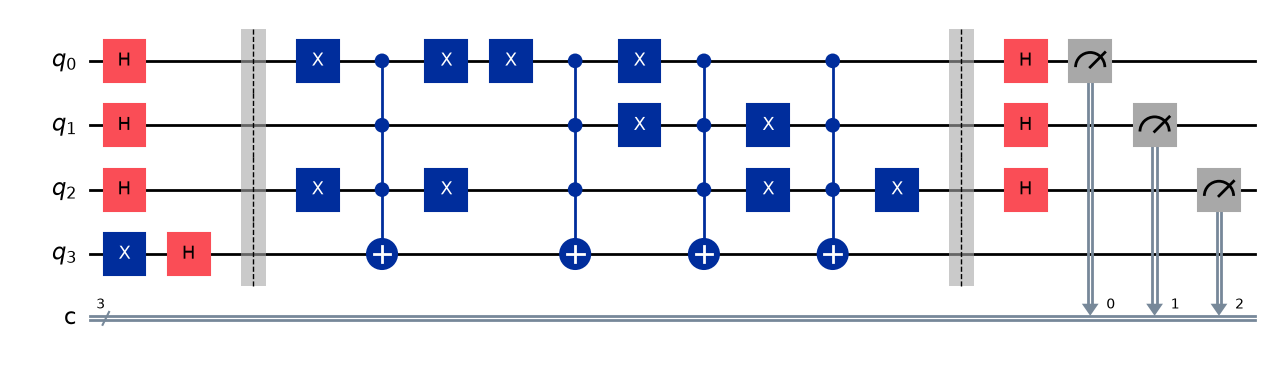

In [24]:
circuit = QuantumCircuit(4, 3)
circuit.h(0)
circuit.h(1)
circuit.h(2)
circuit.x(3)
circuit.h(3)
circuit.barrier()

circuit.x(0)
circuit.x(2)
circuit.mcx([0, 1, 2], 3)
circuit.x(0)
circuit.x(0)
circuit.x(2)
circuit.mcx([0, 1, 2], 3)
circuit.x(0)
circuit.x(1)
circuit.mcx([0, 1, 2], 3)
circuit.x(1)
circuit.x(2)
circuit.mcx([0, 1, 2], 3)
circuit.x(2)
circuit.barrier()

circuit.h(0)
circuit.h(1)
circuit.h(2)

circuit.measure(0, 0)
circuit.measure(1, 1)
circuit.measure(2, 2)
circuit.draw(output='mpl')

In [20]:
state = Statevector(circuit)
state.draw(output='latex')

<IPython.core.display.Latex object>

In [27]:
pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
isa_circuit = pm.run(circuit)

In [28]:
sampler = Sampler(mode=backend)
job = sampler.run([isa_circuit])
print(f"Job ID: {job.job_id()}")

Job ID: db21hjc2ljfc73d3rqu0


In [34]:
results = service.job(job_id='db21hjc2ljfc73d3rqu0').result()
data = results[0].data.c.get_counts()

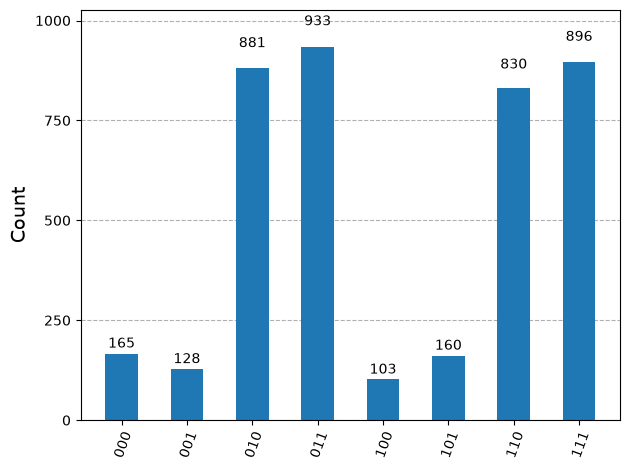

In [35]:
plot_histogram(data=data)